# Lesson 5 — Inference: generating text

⏱ **Duration:** ~30 min &nbsp;|&nbsp; 📚 **Builds on:** Lesson 4 &nbsp;|&nbsp; 💻 **Runs on:** a laptop CPU

**By the end of this lesson you will be able to:**

- turn next-token probabilities into text, one token at a time
- explain temperature, top-k and top-p and see their effect on the distribution
- reproduce a generation with a seed

> 🎤 *Teaching tip:* run the cells in order; every code cell is short enough to be explained live.

## 1. Generation is a loop

```
tokens = [<bos>] + prompt
repeat N times:
    probabilities = model(last block_size tokens)[last position]
    next = sample(probabilities)
    tokens.append(next)
```

The only creative decision is **how to choose `next`** from the probabilities.

In [1]:
import sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))  # lets us `import myllm` without installing it

import torch
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
torch.set_num_threads(4)
DATA = ROOT / "data" / "raw"       # training text lives here
MODELS = ROOT / "models"           # checkpoints are written here

In [2]:
from myllm.generate import load_checkpoint, generate, filter_logits
# use the 10-minute model if you trained it (lesson 8), otherwise the 1-minute model from lesson 4
CKPT = MODELS / "model.pt" if (MODELS / "model.pt").exists() else MODELS / "lesson_tiny.pt"
model, tok, info = load_checkpoint(CKPT)
print(f"loaded {CKPT.name}: {model.num_params():,} params, context {model.cfg.block_size} tokens, vocab {tok.vocab_size}")

loaded model.pt: 1,115,264 params, context 64 tokens, vocab 4000


## 2. What does the model *think* comes next?

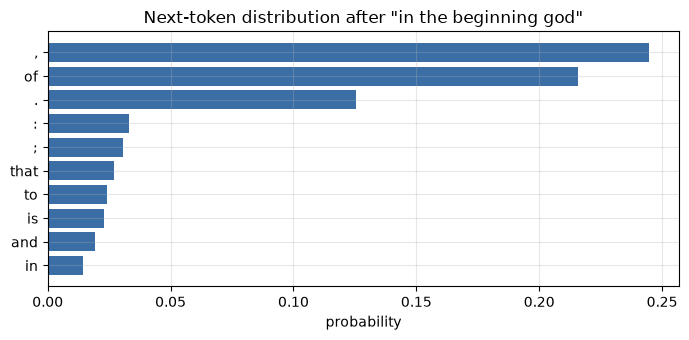

In [3]:
import torch.nn.functional as F
def next_token_probs(prompt):
    ids = [tok.bos_id] + tok.encode(prompt)
    with torch.no_grad():
        logits = model(torch.tensor([ids]))[0][0, -1]
    logits[:4] = float("-inf")                       # never pick special tokens
    return logits

prompt = "in the beginning god"
logits = next_token_probs(prompt)
probs = F.softmax(logits, -1)
top = torch.topk(probs, 10)
plt.figure(figsize=(7, 3.5))
plt.barh([tok.itos[i] for i in top.indices][::-1], top.values.flip(0), color="#3b6ea5")
plt.title(f'Next-token distribution after "{prompt}"'); plt.xlabel("probability")
plt.tight_layout()

## 3. Temperature

Before the softmax the logits are divided by the **temperature** `T`:

* `T → 0` : always pick the most likely word (**greedy**: safe, repetitive)
* `T = 1` : sample from the model's real distribution
* `T > 1` : flatter distribution — more surprising, more mistakes

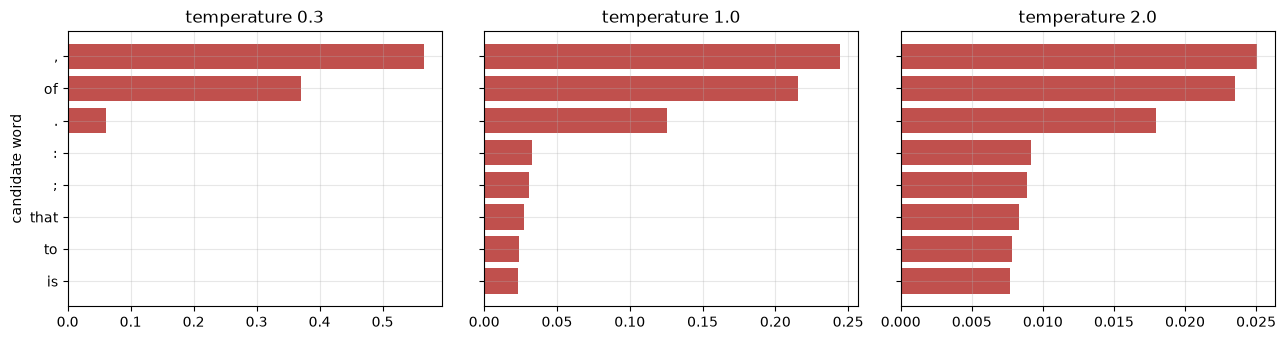

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for a, T in zip(ax, (0.3, 1.0, 2.0)):
    p = F.softmax(logits / T, -1); t = torch.topk(p, 8)
    a.barh([tok.itos[i] for i in t.indices][::-1], t.values.flip(0), color="#c0504d"); a.set_title(f"temperature {T}")
ax[0].set_ylabel("candidate word"); plt.tight_layout()

## 4. Top-k and top-p (nucleus) filtering

Even at `T=1` the long tail of silly words has some probability, and over many steps one gets picked. We cut the tail:

* **top-k**: keep only the *k* most likely words
* **top-p**: keep the smallest set of words whose probabilities add up to *p*

In [5]:
for name, kw in (("no filter", {}), ("top_k=5", dict(top_k=5)), ("top_p=0.9", dict(top_p=0.9))):
    f = filter_logits(logits, **kw)
    n_alive = int(torch.isfinite(f).sum())
    print(f"{name:10s}: {n_alive:5d} candidate words remain (of {tok.vocab_size})")

no filter :  3996 candidate words remain (of 4000)
top_k=5   :     5 candidate words remain (of 4000)
top_p=0.9 :    65 candidate words remain (of 4000)


## 5. Same prompt, different settings

In [6]:
prompt = "the lord said unto"
settings = [("greedy (T=0)", dict(temperature=0)),
            ("balanced (T=0.8, top-k 40, top-p 0.95)", dict()),
            ("creative (T=1.3)", dict(temperature=1.3, top_k=None, top_p=None))]
for name, kw in settings:
    print(f"--- {name}")
    print(generate(model, tok, prompt, max_new_tokens=40, seed=1, **kw), "\n")

--- greedy (T=0)
the lord said unto the lord, and the lord, and the lord, and the lord, and the lord, and the lord, and the lord, and the lord, and the lord, and the lord, and 

--- balanced (T=0.8, top-k 40, top-p 0.95)
the lord said unto the lord, saying, if he shall be a man shall be in his own hand, and the lord will not be destroyed, and the lord shall be afraid of the lord shall be broken. 22 

--- creative (T=1.3)
the lord said unto the left home, write unto another to the country. 33: 17 so thou didst sound a destruction, as afflict thee as pharaoh? because the lord dead; thou previously understanding part over the staff; 



Observe: greedy often **loops** ("the lord of the lord of the lord…"), the creative setting drifts into nonsense.
Reasonable defaults sit in between.

## 6. Reproducibility

Sampling is random, but a **seed** makes it repeatable — essential for tests, demos and lessons.

In [7]:
a = generate(model, tok, "and god said", 25, seed=42)
b = generate(model, tok, "and god said", 25, seed=42)
c = generate(model, tok, "and god said", 25, seed=43)
print("same seed identical     :", a == b)
print("different seed differs  :", a != c)
print(); print(a)

same seed identical     : True
different seed differs  : True

and god said unto you, and say unto us, what i say unto me, i pray me, and will surely be known unto thee


## 7. Limits you should tell your students about

* The model only sees the last `block_size` tokens (its **context window**) — it forgets everything older.
* It has no knowledge besides its tiny training text, and cannot answer questions: it only *continues* text.
* Output is lower-case words: that is the tokenizer's choice, not a bug.

---
## ✅ Key takeaways

- Generation repeatedly samples the next token from the model's probability distribution.
- Temperature reshapes the distribution; top-k / top-p remove unlikely words.
- A seed makes sampling reproducible.

## 🧪 Exercises

1. Generate 5 continuations of the same prompt with different seeds. Which words vary and which stay fixed?
2. Find a prompt on which the model gives a *confident* next word (one bar ≫ others) and one where it is *uncertain*. Why?
3. Give a prompt longer than the context window. What does `generate` do with it? (read `generate.py`)

## ➡️ Next

**Lesson 6 — Evaluation:** measuring quality with numbers instead of impressions.